<!-- solo-notebook -->
<a href="https://colab.research.google.com/github/amenesesy/actividad-cd-liver/blob/main/CD_Actividad1_Liver.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Actividad 1. Tratamiento de datos para la predicción de enfermedades hepáticas

**Programa:** Certificado de Educación Continua en Ciencia de Datos (código C0024), MIU City University Miami

**Autor:** Abel Meneses Yaranga

**Fecha:** 18 de octubre de 2026

**Repositorio del código:** https://github.com/amenesesy/actividad-cd-liver

## Resumen

Este cuaderno resuelve las ocho tareas de la actividad sobre el archivo
`act_liver_disease.csv`, derivado del conjunto Indian Liver Patient Dataset
que emplean Straw y Wu (2022) en su análisis de sesgo por sexo en modelos de
predicción de enfermedad hepática. La Etapa 1 (secciones 1 y 2) describe la
estructura del conjunto y diagnostica sus problemas de calidad. La Etapa 2
(secciones 3 a 8) calcula los estadísticos de dispersión de la bilirrubina,
examina la forma de las distribuciones, construye la matriz de correlación,
imputa los valores faltantes por media y moda, normaliza con Min-Max y Z-Score
y, por último, identifica los valores atípicos con diagramas de caja.

El cuaderno se ejecuta igual en una instalación local que en Google Colab: la
primera celda descarga el conjunto de datos desde el repositorio público si no
está en el directorio de trabajo.

# 0. Configuración del entorno

La primera celda detecta si el cuaderno corre en Google Colab, instala las
librerías que falten y descarga el CSV desde el repositorio del trabajo. La
segunda reúne las librerías, fija la apariencia de las figuras y define el
directorio `figuras/` donde se guardan las imágenes que usa el informe.

In [1]:
# Celda 0.1. Preparación del entorno y compatibilidad con Google Colab.
import importlib.util
import pathlib
import subprocess
import sys
import urllib.request

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

RAW = "https://raw.githubusercontent.com/amenesesy/actividad-cd-liver/main"
CSV = "act_liver_disease.csv"

DEPENDENCIAS = [
    ("numpy", "numpy"), ("pandas", "pandas"), ("matplotlib", "matplotlib"),
    ("seaborn", "seaborn"), ("sklearn", "scikit-learn"), ("scipy", "scipy"),
]
faltantes = [pip for modulo, pip in DEPENDENCIAS
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    print("Instalando dependencias que faltan:", ", ".join(faltantes))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltantes],
                   check=True)

if not pathlib.Path(CSV).exists():
    print("Descargando", CSV, "desde el repositorio del trabajo...")
    urllib.request.urlretrieve(RAW + "/" + CSV, CSV)

print("Entorno de ejecución:", "Google Colab" if EN_COLAB else "instalación local")
print("Versión de Python   :", sys.version.split()[0])
print("Conjunto de datos   :", CSV, "disponible" if pathlib.Path(CSV).exists() else "NO disponible")

Entorno de ejecución: instalación local
Versión de Python   : 3.14.0
Conjunto de datos   : act_liver_disease.csv disponible


In [2]:
# Celda 0.2. Librerías, estilo gráfico y utilidades.
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: "%.3f" % v)

# Paleta de la plantilla del programa: cian corporativo y grises.
CIAN, GRIS, GRIS_CLARO, ACENTO = "#0098CD", "#333333", "#777777", "#E0601E"
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
    "axes.edgecolor": GRIS, "axes.labelcolor": GRIS, "xtick.color": GRIS,
    "ytick.color": GRIS, "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
FIG = pathlib.Path("figuras"); FIG.mkdir(exist_ok=True)
RESULTADOS = {}  # cifras que cita el informe; se vuelcan al final

def guardar(fig, nombre):
    """Guarda la figura en figuras/<nombre>.png y la muestra."""
    fig.savefig(FIG / (nombre + ".png"))
    plt.show()

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.3 | numpy 2.3.5 | seaborn 0.13.2


# Etapa 1. Descripción de la base de datos

## 1. Estructura del dataset (tarea 1)

Se carga el archivo y se describe su formato, tamaño, número de variables y
tipo de dato de cada una. Las abreviaturas de las columnas proceden del
conjunto ILPD: `TB` y `DB` son bilirrubina total y directa (mg/dL); `Alkphos`
es fosfatasa alcalina (UI/L); `Sgpt` y `Sgot` son las transaminasas ALT y AST
(UI/L); `TP` y `ALB` son proteínas totales y albúmina (g/dL); `A/G Ratio` es
el cociente albúmina/globulina; `Selector` es la etiqueta clínica (1 =
paciente con enfermedad hepática, 2 = sin enfermedad).

In [3]:
# Celda 1.1. Carga del archivo y primera inspección.
df = pd.read_csv(CSV)
print("Formato: CSV separado por comas, codificación", "UTF-8/ASCII")
print("Tamaño en disco:", round(pathlib.Path(CSV).stat().st_size / 1024, 1), "KB")
print("Filas x columnas:", df.shape)
print("Memoria en pandas:", round(df.memory_usage(deep=True).sum() / 1024, 1), "KB")
df.head(8)

Formato: CSV separado por comas, codificación UTF-8/ASCII
Tamaño en disco: 24.0 KB
Filas x columnas: (583, 11)
Memoria en pandas: 76.1 KB


,Age,Gender,TB,DB,Alkphos,Sgpt,Sgot,TP,ALB,A/G Ratio,Selector
0,65,Female,0.700,0.100,187,16,18,6.800,3.300,0.900,1
1,62,Male,10.900,5.500,699,64,100,7.500,3.200,0.740,1
2,62,Male,7.300,4.100,490,60,68,7.000,3.300,0.890,1
3,58,Male,1.000,0.400,182,14,20,6.800,3.400,1.000,1
4,72,Male,3.900,2.000,195,27,59,7.300,2.400,0.400,1
5,46,Male,1.800,0.700,208,19,14,7.600,4.400,1.300,1
6,26,Female,0.900,0.200,154,16,12,7.000,3.500,1.000,1
7,29,Female,0.900,0.300,202,14,11,6.700,3.600,1.100,1


In [4]:
# Celda 1.2. Diccionario de variables: tipo de dato, valores únicos y rango.
DICCIONARIO = {
    "Age": ("Edad del paciente (años)", "numérica discreta"),
    "Gender": ("Sexo del paciente", "categórica nominal"),
    "TB": ("Bilirrubina total (mg/dL)", "numérica continua"),
    "DB": ("Bilirrubina directa (mg/dL)", "numérica continua"),
    "Alkphos": ("Fosfatasa alcalina (UI/L)", "numérica discreta"),
    "Sgpt": ("Alanina aminotransferasa ALT (UI/L)", "numérica discreta"),
    "Sgot": ("Aspartato aminotransferasa AST (UI/L)", "numérica discreta"),
    "TP": ("Proteínas totales (g/dL)", "numérica continua"),
    "ALB": ("Albúmina (g/dL)", "numérica continua"),
    "A/G Ratio": ("Cociente albúmina/globulina", "numérica continua"),
    "Selector": ("Etiqueta: 1 enfermo, 2 sano", "categórica binaria (codificada)"),
}
filas = []
for c in df.columns:
    s = df[c]
    rango = "%s a %s" % (s.min(), s.max()) if s.dtype != object and str(s.dtype) != "str" else ", ".join(map(str, s.unique()))
    filas.append((c, DICCIONARIO[c][0], str(s.dtype), DICCIONARIO[c][1], s.nunique(), rango))
tabla_vars = pd.DataFrame(filas, columns=["Variable", "Descripción", "dtype", "Naturaleza", "Únicos", "Rango / valores"])
RESULTADOS["estructura"] = {
    "filas": int(df.shape[0]), "columnas": int(df.shape[1]),
    "kb_disco": round(pathlib.Path(CSV).stat().st_size / 1024, 1),
    "dtypes": {c: str(t) for c, t in df.dtypes.items()},
    "n_num": int(df.select_dtypes("number").shape[1]),
}
tabla_vars

,Variable,Descripción,dtype,Naturaleza,Únicos,Rango / valores
0,Age,Edad del paciente (años),int64,numérica discreta,72,4 a 90
1,Gender,Sexo del paciente,str,categórica nominal,2,"Female, Male"
2,TB,Bilirrubina total (mg/dL),float64,numérica continua,113,0.4 a 75.0
3,DB,Bilirrubina directa (mg/dL),float64,numérica continua,80,0.1 a 19.7
4,Alkphos,Fosfatasa alcalina (UI/L),int64,numérica discreta,263,63 a 2110
5,Sgpt,Alanina aminotransferasa ALT (UI/L),int64,numérica discreta,152,10 a 2000
6,Sgot,Aspartato aminotransferasa AST (UI/L),int64,numérica discreta,177,10 a 4929
7,TP,Proteínas totales (g/dL),float64,numérica continua,58,2.7 a 9.6
8,ALB,Albúmina (g/dL),float64,numérica continua,40,0.9 a 5.5
9,A/G Ratio,Cociente albúmina/globulina,float64,numérica continua,69,0.3 a 2.8


In [5]:
# Celda 1.3. Distribución de las dos variables categóricas: sexo y etiqueta.
sexo = df["Gender"].value_counts()
clase = df["Selector"].value_counts().sort_index()
cruce = pd.crosstab(df["Gender"], df["Selector"], margins=True)
print("Sexo:\n", (sexo.to_frame("n").assign(pct=(100 * sexo / len(df)).round(1))))
print("\nEtiqueta Selector (1 enfermo, 2 sano):\n",
      clase.to_frame("n").assign(pct=(100 * clase / len(df)).round(1)))
print("\nCruce sexo x etiqueta:\n", cruce)
RESULTADOS["categoricas"] = {
    "hombres": int(sexo["Male"]), "mujeres": int(sexo["Female"]),
    "pct_hombres": round(100 * sexo["Male"] / len(df), 1),
    "enfermos": int(clase[1]), "sanos": int(clase[2]),
    "pct_enfermos": round(100 * clase[1] / len(df), 1),
    "pct_enfermos_mujeres": round(100 * cruce.loc["Female", 1] / cruce.loc["Female", "All"], 1),
    "pct_enfermos_hombres": round(100 * cruce.loc["Male", 1] / cruce.loc["Male", "All"], 1),
}

Sexo:
           n    pct
Gender            
Male    441 75.600
Female  142 24.400

Etiqueta Selector (1 enfermo, 2 sano):
             n    pct
Selector            
1         416 71.400
2         167 28.600

Cruce sexo x etiqueta:
 Selector    1    2  All
Gender                 
Female     92   50  142
Male      324  117  441
All       416  167  583


In [6]:
# Celda 1.4. Estadísticos descriptivos globales de las variables numéricas.
desc = df.describe().T
desc["mediana"] = df.median(numeric_only=True)
desc = desc[["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]]
desc

,count,mean,mediana,std,min,25%,50%,75%,max
Age,583.000,44.746,45.000,16.190,4.000,33.000,45.000,58.000,90.000
TB,583.000,3.299,1.000,6.210,0.400,0.800,1.000,2.600,75.000
DB,583.000,1.486,0.300,2.808,0.100,0.200,0.300,1.300,19.700
Alkphos,583.000,290.576,208.000,242.938,63.000,175.500,208.000,298.000,2110.000
Sgpt,583.000,80.714,35.000,182.620,10.000,23.000,35.000,60.500,2000.000
Sgot,583.000,109.911,42.000,288.919,10.000,25.000,42.000,87.000,4929.000
TP,583.000,6.483,6.600,1.085,2.700,5.800,6.600,7.200,9.600
ALB,583.000,3.142,3.100,0.796,0.900,2.600,3.100,3.800,5.500
A/G Ratio,579.000,0.947,0.930,0.320,0.300,0.700,0.930,1.100,2.800
Selector,583.000,1.286,1.000,0.452,1.000,1.000,1.000,2.000,2.000


## 2. Problemas de calidad del dataset (tarea 2)

Se revisan cinco frentes: valores faltantes, filas duplicadas, coherencia
interna entre variables que están relacionadas por definición (la bilirrubina
directa no puede superar a la total; el cociente A/G debería coincidir con
ALB/(TP − ALB)), valores clínicamente extremos y desbalance de las variables
categóricas. Cada hallazgo se cuantifica para que el informe lo cite.

In [7]:
# Celda 2.1. Valores faltantes por columna.
nulos = df.isna().sum()
tabla_nulos = pd.DataFrame({"faltantes": nulos, "pct": (100 * nulos / len(df)).round(2)})
print(tabla_nulos[tabla_nulos.faltantes > 0] if nulos.sum() else "Sin valores faltantes")
print("\nFilas con algún faltante:")
print(df[df.isna().any(axis=1)])
RESULTADOS["faltantes"] = {"total": int(nulos.sum()),
                           "por_columna": {c: int(v) for c, v in nulos.items() if v > 0},
                           "pct_ag": round(100 * nulos["A/G Ratio"] / len(df), 2)}

           faltantes   pct
A/G Ratio          4 0.690

Filas con algún faltante:
     Age  Gender    TB    DB  Alkphos  Sgpt  Sgot    TP   ALB  A/G Ratio  Selector
209   45  Female 0.900 0.300      189    23    33 6.600 3.900        NaN         1
241   51    Male 0.800 0.200      230    24    46 6.500 3.100        NaN         1
253   35  Female 0.600 0.200      180    12    15 5.200 2.700        NaN         2
312   27    Male 1.300 0.600      106    25    54 8.500 4.800        NaN         2


In [8]:
# Celda 2.2. Filas duplicadas exactas.
dup_mask = df.duplicated(keep=False)
n_dup_extra = int(df.duplicated().sum())
print("Filas duplicadas (excedentes respecto de la primera aparición):", n_dup_extra)
print("Filas implicadas en algún duplicado:", int(dup_mask.sum()))
print(df[dup_mask].sort_values(list(df.columns)).head(12))
RESULTADOS["duplicados"] = {"excedentes": n_dup_extra, "implicadas": int(dup_mask.sum())}

Filas duplicadas (excedentes respecto de la primera aparición): 13
Filas implicadas en algún duplicado: 26
     Age Gender    TB    DB  Alkphos  Sgpt  Sgot    TP   ALB  A/G Ratio  Selector
137   18   Male 0.800 0.200      282    72   140 5.500 2.500      0.800         1
138   18   Male 0.800 0.200      282    72   140 5.500 2.500      0.800         1
142   30   Male 1.600 0.400      332    84   139 5.600 2.700      0.900         1
143   30   Male 1.600 0.400      332    84   139 5.600 2.700      0.900         1
173   31   Male 0.600 0.100      175    48    34 6.000 3.700      1.600         1
174   31   Male 0.600 0.100      175    48    34 6.000 3.700      1.600         1
25    34   Male 4.100 2.000      289   875   731 5.000 2.700      1.100         1
26    34   Male 4.100 2.000      289   875   731 5.000 2.700      1.100         1
107   36   Male 0.800 0.200      158    29    39 6.000 2.200      0.500         2
108   36   Male 0.800 0.200      158    29    39 6.000 2.200      0.500  

In [9]:
# Celda 2.3. Coherencia interna: DB <= TB y A/G Ratio frente a ALB/(TP-ALB).
viol_db = df[df["DB"] > df["TB"]]
ag_calc = df["ALB"] / (df["TP"] - df["ALB"])
dif_ag = (df["A/G Ratio"] - ag_calc).abs()
tol = 0.1
inconsist_ag = df.loc[dif_ag > tol, ["TP", "ALB", "A/G Ratio"]].assign(ag_calculado=ag_calc.round(2))
print("Casos con DB > TB (imposibles fisiológicamente):", len(viol_db))
print("Casos con |A/G Ratio - ALB/(TP-ALB)| > %.1f: %d de %d con dato" % (tol, len(inconsist_ag), dif_ag.notna().sum()))
print("Diferencia mediana:", round(dif_ag.median(), 3), "| máxima:", round(dif_ag.max(), 3))
print(inconsist_ag.head(10))
RESULTADOS["coherencia"] = {"db_mayor_tb": int(len(viol_db)), "ag_inconsistentes": int(len(inconsist_ag)),
                            "ag_dif_mediana": round(float(dif_ag.median()), 3), "ag_dif_max": round(float(dif_ag.max()), 3)}

Casos con DB > TB (imposibles fisiológicamente): 3
Casos con |A/G Ratio - ALB/(TP-ALB)| > 0.1: 14 de 579 con dato
Diferencia mediana: 0.031 | máxima: 2.3
       TP   ALB  A/G Ratio  ag_calculado
33  5.600 3.000      0.800         1.150
34  5.600 3.000      0.800         1.150
208 6.100 2.800      0.680         0.850
267 7.400 3.500      1.800         0.900
273 9.600 4.700      1.200         0.960
301 6.700 3.200      0.800         0.910
304 6.900 3.800      1.400         1.230
415 3.600 2.700      0.700         3.000
465 5.100 2.000      0.500         0.650
484 5.000 2.100      1.720         0.720


In [10]:
# Celda 2.4. Valores clínicamente extremos y edad truncada.
# Límites superiores orientativos de lo que se observa en laboratorio clínico
# (se usan solo para señalar registros a revisar, no para borrarlos).
LIMITES = {"TB": 30, "DB": 15, "Alkphos": 1500, "Sgpt": 1500, "Sgot": 1500, "TP": 10, "ALB": 6}
extremos = {c: int((df[c] > lim).sum()) for c, lim in LIMITES.items()}
print("Registros por encima del límite orientativo:", extremos)
print("\nLos 5 valores más altos de Sgot y Sgpt:")
print(df.nlargest(5, "Sgot")[["Age", "Gender", "Sgpt", "Sgot", "Selector"]])
print("\nEdad: mínimo %d, máximo %d; pacientes con 90 años: %d (el ILPD original trunca la edad en 90)"
      % (df.Age.min(), df.Age.max(), (df.Age == 90).sum()))
RESULTADOS["extremos"] = {"por_variable": extremos, "sgot_max": int(df.Sgot.max()), "sgpt_max": int(df.Sgpt.max()),
                          "alkphos_max": int(df.Alkphos.max()), "tb_max": float(df.TB.max()), "edad_90": int((df.Age == 90).sum()),
                          "edad_min": int(df.Age.min())}

Registros por encima del límite orientativo: {'TB': 6, 'DB': 3, 'Alkphos': 7, 'Sgpt': 3, 'Sgot': 3, 'TP': 0, 'ALB': 0}

Los 5 valores más altos de Sgot y Sgpt:
     Age Gender  Sgpt  Sgot  Selector
135   66   Male  1250  4929         1
117   32   Male  2000  2946         1
118   32   Male  1350  1600         1
207   40   Male   950  1500         1
119   32   Male  1250  1050         1

Edad: mínimo 4, máximo 90; pacientes con 90 años: 1 (el ILPD original trunca la edad en 90)


In [11]:
# Celda 2.5. Resumen de calidad.
resumen_calidad = pd.DataFrame([
    ("Valores faltantes", RESULTADOS["faltantes"]["total"], "A/G Ratio, 4 filas (0,69 %)"),
    ("Filas duplicadas exactas", RESULTADOS["duplicados"]["excedentes"], "pacientes con las 11 columnas idénticas"),
    ("DB > TB", RESULTADOS["coherencia"]["db_mayor_tb"], "incoherencia fisiológica"),
    ("A/G distinto de ALB/(TP-ALB) en > 0,1", RESULTADOS["coherencia"]["ag_inconsistentes"], "redondeo o error de captura"),
    ("Sgot > 1500 UI/L", extremos["Sgot"], "valores extremos a confirmar"),
    ("Sgpt > 1500 UI/L", extremos["Sgpt"], "valores extremos a confirmar"),
    ("Alkphos > 1500 UI/L", extremos["Alkphos"], "valores extremos a confirmar"),
    ("Desbalance de sexo", RESULTADOS["categoricas"]["pct_hombres"], "% de hombres"),
    ("Desbalance de clase", RESULTADOS["categoricas"]["pct_enfermos"], "% de enfermos"),
    ("Codificación de Selector", "1 / 2", "no es 0/1; conviene recodificar"),
], columns=["Problema", "Magnitud", "Comentario"])
resumen_calidad

,Problema,Magnitud,Comentario
0,Valores faltantes,4,"A/G Ratio, 4 filas (0,69 %)"
1,Filas duplicadas exactas,13,pacientes con las 11 columnas idénticas
2,DB > TB,3,incoherencia fisiológica
3,"A/G distinto de ALB/(TP-ALB) en > 0,1",14,redondeo o error de captura
4,Sgot > 1500 UI/L,3,valores extremos a confirmar
5,Sgpt > 1500 UI/L,3,valores extremos a confirmar
6,Alkphos > 1500 UI/L,7,valores extremos a confirmar
7,Desbalance de sexo,75.600,% de hombres
8,Desbalance de clase,71.400,% de enfermos
9,Codificación de Selector,1 / 2,no es 0/1; conviene recodificar


# Etapa 2. Tratamiento de datos

## 3. Dispersión de TB y DB (tarea 3)

Media, desviación estándar, varianza, rango y rango intercuartílico de la
bilirrubina total y directa, junto con la mediana y el coeficiente de
variación, que ayudan a leer la variabilidad en términos relativos.

In [12]:
# Celda 3.1. Estadísticos de dispersión de TB y DB.
def dispersion(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "media": s.mean(), "mediana": s.median(), "desv_std": s.std(ddof=1),
        "varianza": s.var(ddof=1), "mínimo": s.min(), "máximo": s.max(),
        "rango": s.max() - s.min(), "Q1": q1, "Q3": q3, "IQR": q3 - q1,
        "coef_variación_%": 100 * s.std(ddof=1) / s.mean(),
    })
tabla_disp = pd.DataFrame({c: dispersion(df[c]) for c in ["TB", "DB"]})
RESULTADOS["dispersion"] = {c: {k: round(float(v), 3) for k, v in tabla_disp[c].items()} for c in tabla_disp}
tabla_disp

,TB,DB
media,3.299,1.486
mediana,1.000,0.300
desv_std,6.210,2.808
varianza,38.558,7.888
mínimo,0.400,0.100
máximo,75.000,19.700
rango,74.600,19.600
Q1,0.800,0.200
Q3,2.600,1.300
IQR,1.800,1.100


In [13]:
# Celda 3.2. Dispersión de TB y DB por clase clínica, para dar contexto a la variabilidad.
por_clase = df.groupby("Selector")[["TB", "DB"]].agg(["mean", "median", "std"]).round(2)
por_clase.index = ["Enfermo (1)", "Sano (2)"]
RESULTADOS["dispersion_clase"] = {
    "tb_media_enf": round(float(df.loc[df.Selector == 1, "TB"].mean()), 2),
    "tb_media_sano": round(float(df.loc[df.Selector == 2, "TB"].mean()), 2),
    "db_media_enf": round(float(df.loc[df.Selector == 1, "DB"].mean()), 2),
    "db_media_sano": round(float(df.loc[df.Selector == 2, "DB"].mean()), 2),
}
por_clase

TB                 DB             
             mean median   std  mean median   std
Enfermo (1) 4.160  1.400 7.140 1.920  0.500 3.210
Sano (2)    1.140  0.800 1.000 0.400  0.200 0.520

## 4. Forma y simetría de TB, DB, Alkphos y Sgpt (tarea 4)

Histogramas en escala original y, para apreciar la estructura que la cola
larga oculta, en escala logarítmica. Los coeficientes de asimetría y curtosis
de Fisher cuantifican lo que la figura muestra; un valor de asimetría próximo
a cero indica simetría y una curtosis positiva, colas más pesadas que la
normal.

In [14]:
# Celda 4.1. Asimetría y curtosis.
VARS4 = ["TB", "DB", "Alkphos", "Sgpt"]
forma = pd.DataFrame({
    "media": df[VARS4].mean(), "mediana": df[VARS4].median(),
    "asimetría": df[VARS4].skew(), "curtosis": df[VARS4].kurt(),
    "asimetría_log": np.log1p(df[VARS4]).skew(),
})
RESULTADOS["forma"] = {c: {k: round(float(v), 2) for k, v in forma.loc[c].items()} for c in VARS4}
forma

,media,mediana,asimetría,curtosis,asimetría_log
TB,3.299,1.000,4.907,37.164,1.728
DB,1.486,0.300,3.212,11.353,1.689
Alkphos,290.576,208.000,3.765,17.753,1.331
Sgpt,80.714,35.000,6.549,50.579,1.474


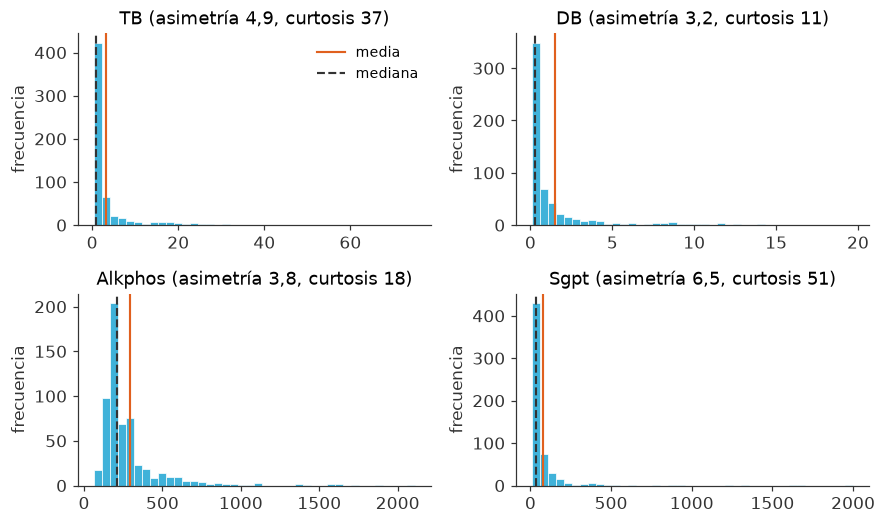

In [15]:
# Celda 4.2. Histogramas en escala original (figura del informe).
fig, axes = plt.subplots(2, 2, figsize=(8.2, 4.9))
for ax, c in zip(axes.ravel(), VARS4):
    sns.histplot(df[c], bins=40, color=CIAN, edgecolor="white", ax=ax)
    ax.axvline(df[c].mean(), color=ACENTO, lw=1.4, label="media")
    ax.axvline(df[c].median(), color=GRIS, lw=1.4, ls="--", label="mediana")
    ax.set_title(("%s (asimetría %.1f, curtosis %.0f)" % (c, forma.loc[c, "asimetría"], forma.loc[c, "curtosis"])).replace(".", ","))
    ax.set_xlabel(""); ax.set_ylabel("frecuencia")
axes[0, 0].legend(frameon=False, fontsize=9)
fig.tight_layout()
guardar(fig, "fig1_histogramas")

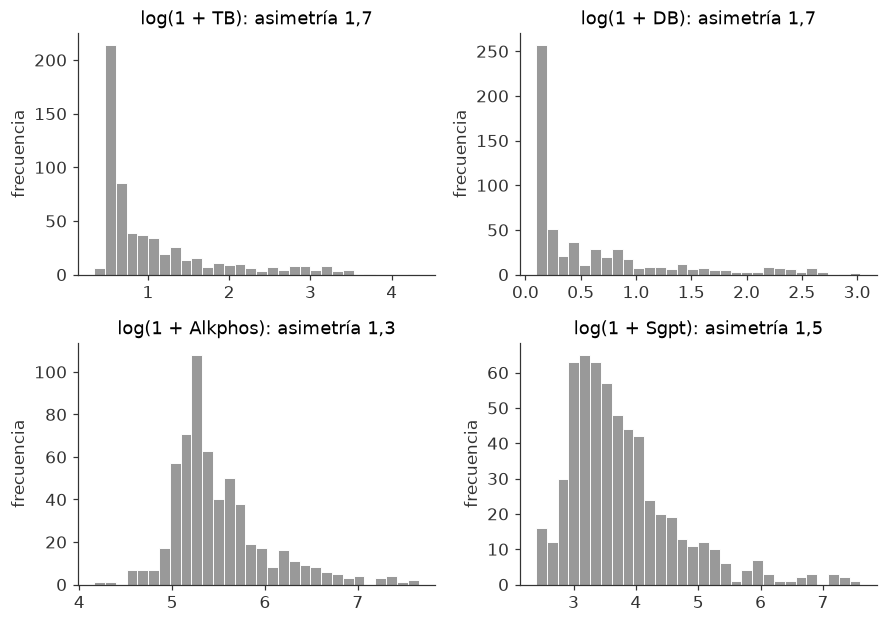

In [16]:
# Celda 4.3. Los mismos histogramas en escala logarítmica, log(1 + x), para ver la estructura de la cola.
fig, axes = plt.subplots(2, 2, figsize=(8.2, 5.8))
for ax, c in zip(axes.ravel(), VARS4):
    sns.histplot(np.log1p(df[c]), bins=30, color=GRIS_CLARO, edgecolor="white", ax=ax)
    ax.set_title(("log(1 + %s): asimetría %.1f" % (c, forma.loc[c, "asimetría_log"])).replace(".", ","))
    ax.set_xlabel(""); ax.set_ylabel("frecuencia")
fig.tight_layout()
guardar(fig, "fig1b_histogramas_log")

## 5. Relaciones entre variables: matriz de correlación (tarea 5)

Se recodifican las dos variables categóricas (`Gender` a 0/1 y `Selector` a
0 = sano, 1 = enfermo) para incluirlas en la matriz. Dadas las fuertes
asimetrías de la sección anterior, se calcula la correlación de Pearson, que
es la que pide la actividad, y también la de Spearman, que no depende de la
escala y es robusta a los valores extremos. Las parejas con |r| mayor o igual
a 0,5 se listan con su valor p.

In [17]:
# Celda 5.1. Matrices de Pearson y de Spearman.
num = df.copy()
num["Gender"] = (num["Gender"] == "Male").astype(int)       # 1 = hombre
num["Enfermo"] = (num["Selector"] == 1).astype(int)          # 1 = enfermo
num = num.drop(columns="Selector")
corr_p = num.corr(method="pearson")
corr_s = num.corr(method="spearman")

pares = []
cols = corr_p.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        a, b = cols[i], cols[j]
        x = num[[a, b]].dropna()
        r, p = stats.pearsonr(x[a], x[b])
        rho, _ = stats.spearmanr(x[a], x[b])
        pares.append((a, b, r, rho, p))
pares = pd.DataFrame(pares, columns=["var_1", "var_2", "pearson", "spearman", "p_pearson"])
fuertes = pares[pares.pearson.abs() >= 0.5].sort_values("pearson", key=abs, ascending=False)
print("Parejas con |r de Pearson| >= 0,5:")
print(fuertes.to_string(index=False, float_format=lambda v: "%.3f" % v))
print("\nCorrelación de cada variable con la etiqueta Enfermo (Pearson / Spearman):")
con_clase = pd.DataFrame({"pearson": corr_p["Enfermo"], "spearman": corr_s["Enfermo"]}).drop("Enfermo").sort_values("pearson", key=abs, ascending=False)
print(con_clase.round(3))
RESULTADOS["correlacion"] = {
    "fuertes": [{"a": r.var_1, "b": r.var_2, "r": round(r.pearson, 3), "rho": round(r.spearman, 3)} for r in fuertes.itertuples()],
    "con_clase": {k: round(float(v), 3) for k, v in corr_p["Enfermo"].drop("Enfermo").items()},
    "con_clase_spearman": {k: round(float(v), 3) for k, v in corr_s["Enfermo"].drop("Enfermo").items()},
    "sgpt_sgot_spearman": round(float(corr_s.loc["Sgpt", "Sgot"]), 3),
}

Parejas con |r de Pearson| >= 0,5:
var_1     var_2  pearson  spearman  p_pearson
   TB        DB    0.875     0.959      0.000
 Sgpt      Sgot    0.792     0.774      0.000
   TP       ALB    0.784     0.779      0.000
  ALB A/G Ratio    0.690     0.754      0.000

Correlación de cada variable con la etiqueta Enfermo (Pearson / Spearman):
           pearson  spearman
DB           0.246     0.297
TB           0.220     0.304
Alkphos      0.185     0.273
Sgpt         0.163     0.291
A/G Ratio   -0.163    -0.189
ALB         -0.161    -0.167
Sgot         0.152     0.309
Age          0.137     0.130
Gender       0.082     0.082
TP          -0.035    -0.032


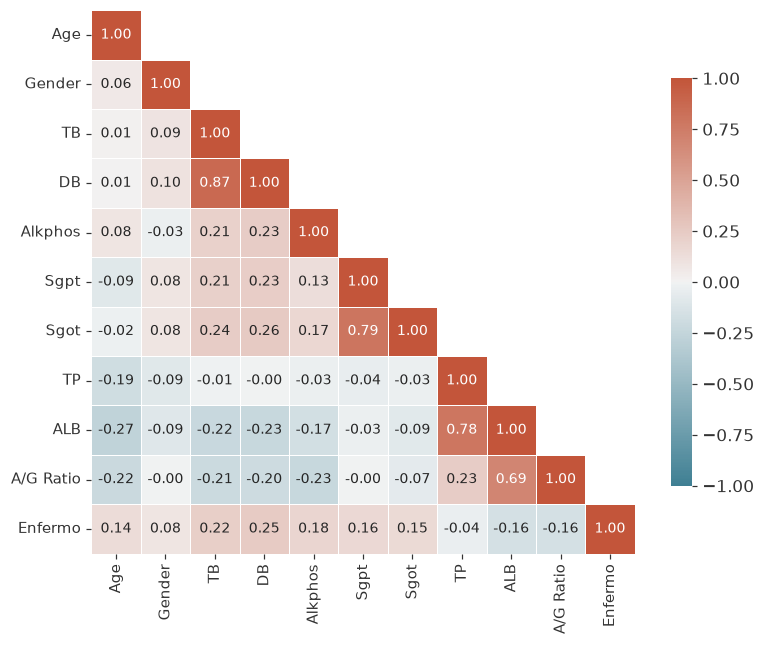

In [18]:
# Celda 5.2. Mapa de calor de la matriz de Pearson (figura del informe).
mask = np.triu(np.ones_like(corr_p, dtype=bool), k=1)
cmap = sns.diverging_palette(220, 20, as_cmap=True)
def mapa_calor(m, titulo, nombre):
    fig, ax = plt.subplots(figsize=(7.6, 6.0))
    sns.heatmap(m, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
                annot_kws={"size": 9}, square=True, linewidths=0.4, cbar_kws={"shrink": 0.75}, ax=ax)
    ax.tick_params(labelsize=10)  # sin título interno: el título APA va fuera de la imagen
    fig.tight_layout()
    guardar(fig, nombre)
mapa_calor(corr_p, "Correlación de Pearson", "fig2_correlacion")

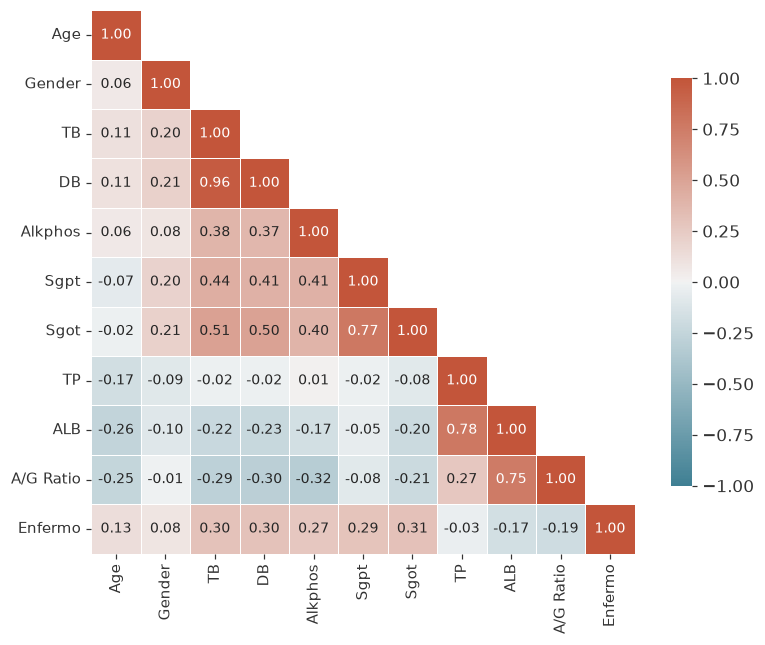

In [19]:
# Celda 5.3. Mapa de calor de la matriz de Spearman, robusta a los valores extremos.
mapa_calor(corr_s, "Correlación de Spearman", "fig2b_correlacion_spearman")

## 6. Imputación de valores faltantes por media y moda (tarea 6)

Los cuatro faltantes están en `A/G Ratio`. Se aplica el procedimiento
general que pide la actividad: media para las columnas numéricas y moda para
las no numéricas (aquí `Gender`, que no tiene faltantes, de modo que la moda
se calcula y se deja preparada sin alterar nada). Se compara la distribución
antes y después y se contrasta con dos alternativas, la mediana y el valor
que se deduce de ALB y TP, para discutir las ventajas y desventajas.

In [20]:
# Celda 6.1. Imputación por media (numéricas) y moda (no numéricas).
df_imp = df.copy()
num_cols = df_imp.select_dtypes("number").columns.drop("Selector")
cat_cols = [c for c in df_imp.columns if c not in num_cols and c != "Selector"]

medias = df_imp[num_cols].mean()
modas = {c: df_imp[c].mode()[0] for c in cat_cols}
print("Medias usadas (solo se aplican donde hay faltantes):")
print(medias.round(3).to_string())
print("\nModas de las no numéricas:", modas)

df_imp[num_cols] = df_imp[num_cols].fillna(medias)
for c in cat_cols:
    df_imp[c] = df_imp[c].fillna(modas[c])

print("\nFaltantes después de imputar:", int(df_imp.isna().sum().sum()))
idx = df[df["A/G Ratio"].isna()].index
comparacion = pd.DataFrame({
    "TP": df.loc[idx, "TP"], "ALB": df.loc[idx, "ALB"],
    "imputado_media": df_imp.loc[idx, "A/G Ratio"].round(3),
    "mediana_alternativa": df["A/G Ratio"].median(),
    "ALB/(TP-ALB)": (df.loc[idx, "ALB"] / (df.loc[idx, "TP"] - df.loc[idx, "ALB"])).round(3),
})
print("\nLas cuatro filas imputadas frente a dos alternativas:")
print(comparacion)
antes, despues = df["A/G Ratio"].describe(), df_imp["A/G Ratio"].describe()
print("\nA/G Ratio antes y después (media, std, mediana):")
print(pd.DataFrame({"antes": antes, "después": despues}).loc[["count", "mean", "std", "50%"]].round(4))
RESULTADOS["imputacion"] = {
    "media_ag": round(float(medias["A/G Ratio"]), 4), "mediana_ag": round(float(df["A/G Ratio"].median()), 3),
    "std_antes": round(float(antes["std"]), 4), "std_despues": round(float(despues["std"]), 4),
    "moda_gender": modas["Gender"],
    "filas": [{"TP": float(r.TP), "ALB": float(r.ALB), "calc": float(r._5)} for r in comparacion.itertuples()],
}

Medias usadas (solo se aplican donde hay faltantes):
Age          44.746
TB            3.299
DB            1.486
Alkphos     290.576
Sgpt         80.714
Sgot        109.911
TP            6.483
ALB           3.142
A/G Ratio     0.947

Modas de las no numéricas: {'Gender': 'Male'}

Faltantes después de imputar: 0

Las cuatro filas imputadas frente a dos alternativas:
       TP   ALB  imputado_media  mediana_alternativa  ALB/(TP-ALB)
209 6.600 3.900           0.947                0.930         1.444
241 6.500 3.100           0.947                0.930         0.912
253 5.200 2.700           0.947                0.930         1.080
312 8.500 4.800           0.947                0.930         1.297

A/G Ratio antes y después (media, std, mediana):
        antes  después
count 579.000  583.000
mean    0.947    0.947
std     0.320    0.319
50%     0.930    0.947


## 7. Normalización Min-Max y Z-Score (tarea 7)

Sobre el DataFrame ya imputado se escalan las nueve variables numéricas de
entrada (la etiqueta `Selector` se excluye porque es la variable objetivo).
Min-Max lleva cada variable al intervalo [0, 1]; Z-Score la centra en cero
con desviación estándar uno. Se muestran los estadísticos resultantes y una
figura que compara la misma variable asimétrica (`Sgot`) bajo las dos
transformaciones.

In [21]:
# Celda 7.1. Aplicación de MinMaxScaler y StandardScaler (scikit-learn).
X = df_imp[num_cols]
minmax = MinMaxScaler().fit(X)
zscore = StandardScaler().fit(X)
X_mm = pd.DataFrame(minmax.transform(X), columns=num_cols, index=X.index)
X_z = pd.DataFrame(zscore.transform(X), columns=num_cols, index=X.index)

print("Min-Max: mínimo, máximo, media y mediana por variable")
print(pd.DataFrame({"min": X_mm.min(), "max": X_mm.max(), "media": X_mm.mean(), "mediana": X_mm.median()}).round(3))
print("\nZ-Score: media, desviación, mínimo y máximo por variable")
print(pd.DataFrame({"media": X_z.mean().round(10), "std": X_z.std(ddof=0), "min": X_z.min(), "max": X_z.max()}).round(3))
RESULTADOS["normalizacion"] = {
    "mm_media_sgot": round(float(X_mm["Sgot"].mean()), 4), "mm_mediana_sgot": round(float(X_mm["Sgot"].median()), 4),
    "mm_media_age": round(float(X_mm["Age"].mean()), 3),
    "z_max_sgot": round(float(X_z["Sgot"].max()), 2), "z_max_sgpt": round(float(X_z["Sgpt"].max()), 2),
    "z_max_tb": round(float(X_z["TB"].max()), 2), "z_min_age": round(float(X_z["Age"].min()), 2),
    "z_max_age": round(float(X_z["Age"].max()), 2),
}
X_mm.head()

Min-Max: mínimo, máximo, media y mediana por variable
            min   max  media  mediana
Age       0.000 1.000  0.474    0.477
TB        0.000 1.000  0.039    0.008
DB        0.000 1.000  0.071    0.010
Alkphos   0.000 1.000  0.111    0.071
Sgpt      0.000 1.000  0.036    0.013
Sgot      0.000 1.000  0.020    0.007
TP        0.000 1.000  0.548    0.565
ALB       0.000 1.000  0.487    0.478
A/G Ratio 0.000 1.000  0.259    0.259

Z-Score: media, desviación, mínimo y máximo por variable
           media   std    min    max
Age        0.000 1.000 -2.519  2.798
TB         0.000 1.000 -0.467 11.557
DB         0.000 1.000 -0.494  6.491
Alkphos   -0.000 1.000 -0.938  7.496
Sgpt      -0.000 1.000 -0.388 10.519
Sgot       0.000 1.000 -0.346 16.694
TP         0.000 1.000 -3.488  2.874
ALB        0.000 1.000 -2.821  2.967
A/G Ratio  0.000 1.000 -2.033  5.823


,Age,TB,DB,Alkphos,Sgpt,Sgot,TP,ALB,A/G Ratio
0,0.709,0.004,0.000,0.061,0.003,0.002,0.594,0.522,0.240
1,0.674,0.141,0.276,0.311,0.027,0.018,0.696,0.500,0.176
2,0.674,0.092,0.204,0.209,0.025,0.012,0.623,0.522,0.236
3,0.628,0.008,0.015,0.058,0.002,0.002,0.594,0.543,0.280
4,0.791,0.047,0.097,0.064,0.009,0.010,0.667,0.326,0.040


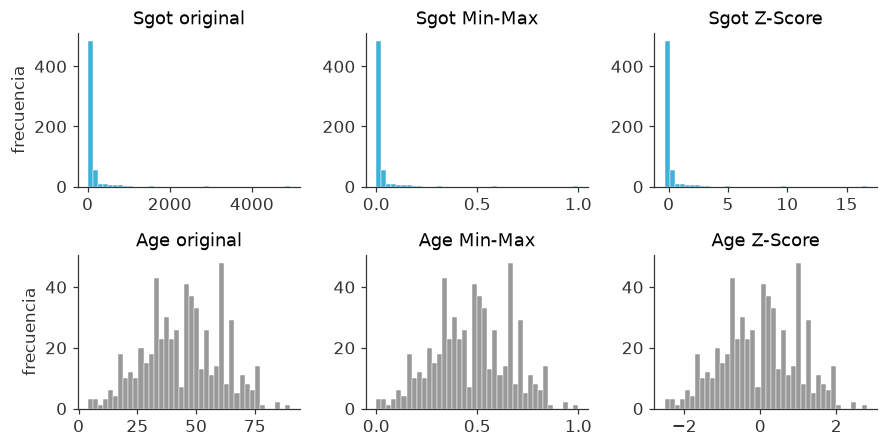

In [22]:
# Celda 7.2. Comparación visual: Sgot original, Min-Max y Z-Score, y la edad como contraste simétrico.
fig, axes = plt.subplots(2, 3, figsize=(8.2, 4.2))
for i, (c, col) in enumerate([("Sgot", CIAN), ("Age", GRIS_CLARO)]):
    for j, (serie, titulo) in enumerate([(X[c], "original"), (X_mm[c], "Min-Max"), (X_z[c], "Z-Score")]):
        ax = axes[i, j]
        sns.histplot(serie, bins=40, color=col, edgecolor="white", ax=ax)
        ax.set_title("%s %s" % (c, titulo)); ax.set_xlabel(""); ax.set_ylabel("frecuencia" if j == 0 else "")
fig.tight_layout()
guardar(fig, "fig3_normalizacion")

## 8. Valores atípicos en Sgot, TP, ALB y A/G Ratio (tarea 8)

Diagramas de caja de las cuatro variables, en conjunto y separados por
etiqueta clínica. Se cuentan los valores atípicos con la regla de Tukey
(fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]) y los extremos (factor 3), y se
indica hacia qué lado caen. Para `Sgot`, cuya cola aplasta el gráfico, se
añade la versión en escala logarítmica.

In [23]:
# Celda 8.1. Conteo de atípicos con la regla de Tukey (1,5 IQR) y extremos (3 IQR).
VARS8 = ["Sgot", "TP", "ALB", "A/G Ratio"]
def atipicos(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return lo, hi, int((s < lo).sum()), int((s > hi).sum())
filas = []
for c in VARS8:
    s = df_imp[c]
    lo, hi, nb, na = atipicos(s)
    _, _, nb3, na3 = atipicos(s, 3)
    enf = df_imp.loc[(s < lo) | (s > hi), "Selector"].eq(1).mean() * 100 if (nb + na) else np.nan
    filas.append((c, round(lo, 2), round(hi, 2), nb, na, nb + na, round(100 * (nb + na) / len(s), 1), nb3 + na3, round(enf, 1)))
tabla_out = pd.DataFrame(filas, columns=["Variable", "límite_inf", "límite_sup", "bajo", "alto", "total", "pct", "extremos_3IQR", "pct_enfermos_entre_atípicos"])
RESULTADOS["atipicos"] = {r.Variable: {"lo": r.límite_inf, "hi": r.límite_sup, "bajo": r.bajo, "alto": r.alto, "total": r.total,
                                       "pct": r.pct, "extremos": r.extremos_3IQR, "pct_enf": r.pct_enfermos_entre_atípicos}
                          for r in tabla_out.itertuples()}
RESULTADOS["atipicos"]["pct_enfermos_global"] = RESULTADOS["categoricas"]["pct_enfermos"]
tabla_out

,Variable,límite_inf,límite_sup,bajo,alto,total,pct,extremos_3IQR,pct_enfermos_entre_atípicos
0,Sgot,-68.000,180.000,0,66,66,11.300,42,97.000
1,TP,3.700,9.300,6,2,8,1.400,0,100.000
2,ALB,0.800,5.600,0,0,0,0.000,0,NaN
3,A/G Ratio,0.100,1.700,0,10,10,1.700,3,60.000


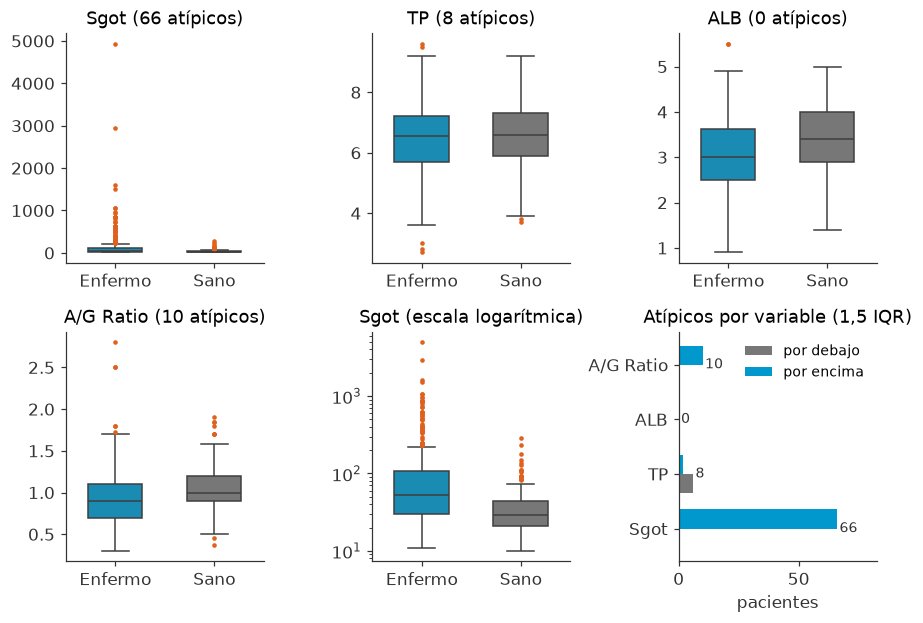

In [24]:
# Celda 8.2. Diagramas de caja por variable y por clase clínica.
fig, axes = plt.subplots(2, 3, figsize=(8.2, 5.8))
axes = axes.ravel()
etiq = df_imp["Selector"].map({1: "Enfermo", 2: "Sano"})
pal = {"Enfermo": CIAN, "Sano": GRIS_CLARO}
flier = {"marker": "o", "markersize": 3, "markerfacecolor": ACENTO, "markeredgecolor": "none"}
for ax, c in zip(axes[:4], VARS8):
    sns.boxplot(x=etiq, y=df_imp[c], hue=etiq, palette=pal, legend=False, width=0.55, flierprops=flier, ax=ax)
    ax.set_title("%s (%d atípicos)" % (c, RESULTADOS["atipicos"][c]["total"])); ax.set_xlabel(""); ax.set_ylabel("")
ax = axes[4]
sns.boxplot(x=etiq, y=df_imp["Sgot"], hue=etiq, palette=pal, legend=False, width=0.55, flierprops=flier, ax=ax)
ax.set_yscale("log"); ax.set_title("Sgot (escala logarítmica)"); ax.set_xlabel(""); ax.set_ylabel("")
# Sexto panel: recuento de atípicos por variable y por lado, con la regla de 1,5 IQR.
ax = axes[5]
conteo = tabla_out.set_index("Variable")[["bajo", "alto"]]
conteo.plot.barh(ax=ax, color=[GRIS_CLARO, CIAN], width=0.7, edgecolor="none")
for i, (b, a) in enumerate(zip(conteo["bajo"], conteo["alto"])):
    ax.text(max(a, b) + 1, i, "%d" % (a + b), va="center", fontsize=9, color=GRIS)
ax.set_title("Atípicos por variable (1,5 IQR)"); ax.set_ylabel(""); ax.set_xlabel("pacientes")
ax.legend(["por debajo", "por encima"], frameon=False, fontsize=9); ax.set_xlim(0, conteo.sum(axis=1).max() * 1.25)
fig.tight_layout()
guardar(fig, "fig4_boxplots")

# 9. Conjunto de datos preparado y exportación de resultados

Se guarda el DataFrame imputado y las dos versiones normalizadas, y se vuelcan
a `resultados.json` todas las cifras que cita el informe, de modo que texto y
código no puedan contradecirse.

In [25]:
# Celda 9.1. Exportación del dataset tratado y de las cifras del informe.
df_imp.to_csv("liver_imputado.csv", index=False)
X_mm.assign(Selector=df_imp["Selector"]).to_csv("liver_minmax.csv", index=False)
X_z.assign(Selector=df_imp["Selector"]).to_csv("liver_zscore.csv", index=False)
with open("resultados.json", "w", encoding="utf-8") as fh:
    json.dump(RESULTADOS, fh, ensure_ascii=False, indent=1, default=float)
print("Archivos escritos: liver_imputado.csv, liver_minmax.csv, liver_zscore.csv, resultados.json")
print("Figuras en", FIG.resolve(), ":", sorted(p.name for p in FIG.glob("*.png")))

Archivos escritos: liver_imputado.csv, liver_minmax.csv, liver_zscore.csv, resultados.json
Figuras en D:\Abel\MAESTRIA IA\Ciencia de Datos\actividad 1\actividad 1\trabajo\figuras : ['fig1_histogramas.png', 'fig1b_histogramas_log.png', 'fig2_correlacion.png', 'fig2b_correlacion_spearman.png', 'fig3_normalizacion.png', 'fig4_boxplots.png']
